In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from skimage.metrics import structural_similarity
from scipy.interpolate import interp1d, CubicSpline

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def calculate_ssim(reference, estimate):
    reference = np.asarray(reference, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)

    if reference.shape != estimate.shape:
        raise ValueError("Image shapes must match.")

    data_range = float(np.max(reference) - np.min(reference))

    if data_range <= 0:
        raise ValueError("Reference image must have a non-zero range.")

    min_dim = min(reference.shape)
    win_size = min(7, min_dim if min_dim % 2 else min_dim - 1)

    if win_size < 3:
        raise ValueError("Images must be at least 3x3.")

    return float(
        structural_similarity(
            reference,
            estimate,
            data_range=data_range,
            win_size=win_size
        )
    )

print("SSIM function is ready.")

SSIM function is ready.


In [2]:
num_sensors = 32
num_samples = 600

fs = 10e6
dt = 1 / fs
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
time = np.arange(num_samples) * dt

signals = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c

    signals[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)


def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )
        indices = np.rint((distance_map / c) / dt).astype(int)

        valid = (indices >= 0) & (indices < num_samples)
        sampled = np.zeros_like(X, dtype=float)
        sampled[valid] = signal_matrix[i, indices[valid]]

        image += sampled

    return image


reference_image = reconstruct_das(signals)

print("Reference image:", reference_image.shape)

Reference image: (100, 100)


In [3]:
dropout_counts = [4, 8, 12]

rng = np.random.default_rng(42)
dropout_order = rng.permutation(num_sensors)

results = {
    "reference": "Full-array DAS image",
    "dropout_counts": dropout_counts,
    "inactive_sensor_order": dropout_order.tolist(),
    "ssim": {
        "Incomplete": [],
        "Linear": [],
        "Spline": []
    }
}

for n_inactive in dropout_counts:
    inactive_indices = np.sort(dropout_order[:n_inactive])
    active_indices = np.setdiff1d(
        np.arange(num_sensors),
        inactive_indices
    )

    damaged_signals = signals.copy()
    damaged_signals[inactive_indices, :] = 0.0

    # No interpolation
    incomplete_image = reconstruct_das(damaged_signals)

    # Linear interpolation
    linear_signals = damaged_signals.copy()

    linear_interp = interp1d(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    linear_signals[inactive_indices, :] = linear_interp(
        sensor_x[inactive_indices]
    )

    # Cubic spline interpolation
    spline_signals = damaged_signals.copy()

    spline_interp = CubicSpline(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        extrapolate=True
    )

    spline_signals[inactive_indices, :] = spline_interp(
        sensor_x[inactive_indices]
    )

    linear_image = reconstruct_das(linear_signals)
    spline_image = reconstruct_das(spline_signals)

    # Calculate SSIM against the same reference
    scores = {
        "Incomplete": calculate_ssim(
            reference_image, incomplete_image
        ),
        "Linear": calculate_ssim(
            reference_image, linear_image
        ),
        "Spline": calculate_ssim(
            reference_image, spline_image
        )
    }

    for method, score in scores.items():
        results["ssim"][method].append(score)

    print(f"\nInactive sensors: {n_inactive}/32")
    for method, score in scores.items():
        print(f"{method} SSIM: {score:.6f}")


Inactive sensors: 4/32
Incomplete SSIM: 0.974596
Linear SSIM: 0.999973
Spline SSIM: 1.000000

Inactive sensors: 8/32
Incomplete SSIM: 0.928679
Linear SSIM: 0.999932
Spline SSIM: 1.000000

Inactive sensors: 12/32
Incomplete SSIM: 0.821022
Linear SSIM: 0.999758
Spline SSIM: 0.999995


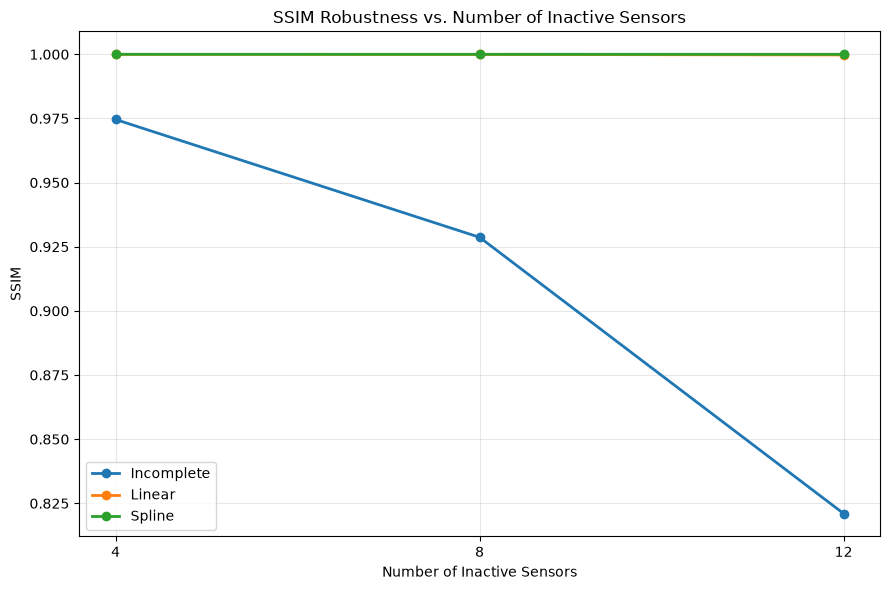

In [4]:
plt.figure(figsize=(9, 6))

for method, values in results["ssim"].items():
    plt.plot(
        dropout_counts,
        values,
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Number of Inactive Sensors")
plt.ylabel("SSIM")
plt.title("SSIM Robustness vs. Number of Inactive Sensors")
plt.xticks(dropout_counts)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/day48_ssim_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
results["inactive_sensor_percentages"] = [
    100 * n / num_sensors for n in dropout_counts
]

with open(
    OUTPUT_DIR / "day48_ssim_robustness_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print(
    "JSON saved:",
    OUTPUT_DIR / "day48_ssim_robustness_results.json"
)
print("Plot saved: ../outputs/day48_ssim_robustness.png")

JSON saved: ..\outputs\day48_ssim_robustness_results.json
Plot saved: ../outputs/day48_ssim_robustness.png
